# Independent Soft Actor-Critic (SAC) baseline

This notebook trains **one SAC policy for each building** in the local CityLearn environment. It is the first learned baseline after `BasicRBC`.

The goals are to:

1. verify that the complete training and evaluation pipeline works;
2. understand CityLearn's exploration, replay buffer, and deterministic evaluation stages; and
3. produce reproducible outputs that can later be compared with RBC, MARLISA, and the proposed carbon-aware fairness reward.


## What makes this independent SAC?

`central_agent=False` gives CityLearn one observation vector, action vector, replay buffer, actor, and pair of critics per building. The policies train at the same time, but each policy acts only for its own building.

In CityLearn `IndependentSACReward` is the reward function designed for decntralized SAC agents that learn independently, one building at a time, without sharing information through the reward.

Key Idea: Each Building gets a rewards based only on its own grid electricity consumption, not on what the other buildings are doing. That is "What happens if every building simple learns to optimize its own grid consumption?"

For building $i$, CityLearn’s current source effectively computes:
$$
r_i(t)= -\max(E_i(t),0)
$$
where $E_i(t)$ is that building’s net_electricity_consumption. Positive $E_i$ means the building is importing electricity from the grid; negative $E_i$ means net export. The source code returns zero reward for export and a negative penalty for positive grid import.

Therefore the agent will learn: For my own building, try to reduce positive grid electricity import. Over many interactions, the actor learns actions that produce higher long-term reward, which here essentially means less positive grid electricity consumption.


This baseline uses CityLearn's `IndependentSACReward`, which is approximately `-max(net_electricity_consumption, 0)` for each building. It penalizes grid imports and gives no positive reward for export. It does **not** explicitly optimize carbon intensity, thermal comfort, or fairness. Those omissions make it a useful reference for the later custom reward.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# This works whether Jupyter starts in the project root or notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.run_independent_sac import run_independent_sac

SCHEMA = PROJECT_ROOT / 'notebooks' / 'data' / 'schema.json'
OUTPUT_DIRECTORY = PROJECT_ROOT / 'outputs' / 'independent_sac'
print(f'Project root: {PROJECT_ROOT}')
print(f'Schema exists: {SCHEMA.is_file()}')


Project root: C:\Users\tanka\Dropbox\08-1 NUS Master in Computing AI specialization\CS5546 AI Planning and Decision Making\02Assignment
Schema exists: True


## Experiment configuration

With three episodes, the run has one initial exploration episode, one learning episode, and one deterministic evaluation episode. This is enough to test the implementation, but it is too little training for a research conclusion. Once the pipeline is stable, increase `TRAINING_EPISODES` and repeat the experiment over multiple fixed seeds.

Set `REWARD = 'schema'` only when you intentionally want the dataset's configured `ComfortReward` instead. Record this setting because changing the reward changes the learning problem.


In [2]:
SEED = 42
TRAINING_EPISODES = 3
REWARD = 'independent_sac'  # Alternative: 'schema'

SAC_PARAMETERS = {
    'hidden_dimension': (256, 256), # Uses two hidden neural-network layers with 256 neurons each.
    'discount': 0.99, # Gives high importance to future rewards when learning long-term decisions.
    'tau': 0.005, #Controls how slowly the target networks are updated for stable learning.
    'alpha': 0.2, #Controls the importance of exploration/entropy in SAC.
    'learning_rate': 3e-4, #Determines how quickly the neural-network weights are updated.
    'batch_size': 256, #Trains the networks using 256 past experiences per update.
    'replay_buffer_capacity': 100_000, #Stores up to 100,000 past transitions for experience replay.
    'action_scaling_coefficient': 0.5, #5	Scales the agent's output actions to limit their magnitude.
    'reward_scaling': 5.0, #Multiplies rewards to improve the numerical scale used during learning.
    'update_per_time_step': 1, #Performs one neural-network update for every environment timestep.
}

pd.Series({'seed': SEED, 'episodes': TRAINING_EPISODES, 'reward': REWARD, **SAC_PARAMETERS})


seed                                       42
episodes                                    3
reward                        independent_sac
hidden_dimension                   (256, 256)
discount                                 0.99
tau                                     0.005
alpha                                     0.2
learning_rate                          0.0003
batch_size                                256
replay_buffer_capacity                 100000
action_scaling_coefficient                0.5
reward_scaling                            5.0
update_per_time_step                        1
dtype: object

## Train and evaluate

CityLearn's default schedule waits for roughly one full episode before standardizing observations and rewards. Random actions fill the replay buffer during that period. The final episode is deterministic, so it evaluates the actor means and does not update the neural networks.

Training SAC is much slower than running RBC because every building updates two critics and an actor. Start with the three-episode pipeline check below before starting longer experiments.


In [3]:
result = run_independent_sac(
    schema=SCHEMA,
    output_directory=OUTPUT_DIRECTORY,
    episodes=TRAINING_EPISODES,
    random_seed=SEED,
    reward=REWARD,
    **SAC_PARAMETERS,
)

env = result['env']
agent = result['agent']
print(f"Device: {agent.device}")
print(f"Policies: {len(agent.policy_net)} (one per building)")
print(f"Reward function: {type(env.reward_function).__name__}")
print(f"Outputs: {result['output_directory']}")


Device: cpu
Policies: 3 (one per building)
Reward function: IndependentSACReward
Outputs: C:\Users\tanka\Dropbox\08-1 NUS Master in Computing AI specialization\CS5546 AI Planning and Decision Making\02Assignment\outputs\independent_sac


## Training rewards

The figure shows total reward per building and episode. Compare trends only within runs that use the same reward function. The last point is deterministic evaluation rather than another training episode. Three points are a pipeline check, not evidence of convergence.


,episode,phase,building,min,max,sum,mean
0,1,initial_exploration,Building_1,-7.713,0.0,-1087.782,-1.513
1,1,initial_exploration,Building_2,-10.483,0.0,-673.360,-0.937
2,1,initial_exploration,Building_3,-10.420,0.0,-930.556,-1.294
3,2,training,Building_1,-7.763,0.0,-509.579,-0.709
4,2,training,Building_2,-9.269,0.0,-316.256,-0.440
5,2,training,Building_3,-10.664,0.0,-553.575,-0.770
6,3,deterministic_evaluation,Building_1,-7.886,0.0,-428.830,-0.596
7,3,deterministic_evaluation,Building_2,-8.860,0.0,-252.266,-0.351
8,3,deterministic_evaluation,Building_3,-9.442,0.0,-493.017,-0.686


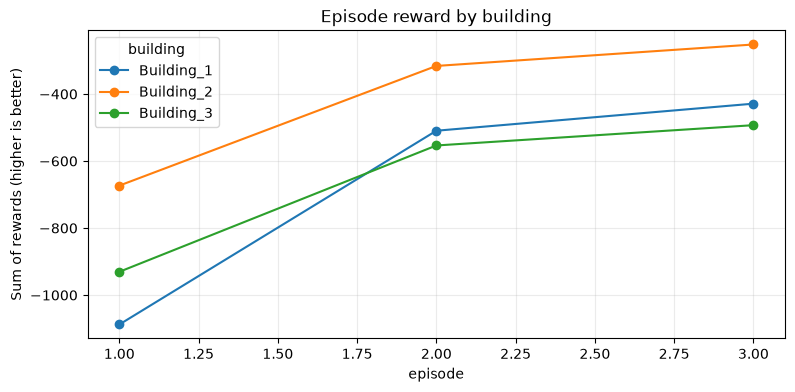

In [4]:
training_rewards = result['training_rewards']
display(training_rewards.round(3))

reward_plot = training_rewards.pivot(index='episode', columns='building', values='sum')
ax = reward_plot.plot(marker='o', figsize=(9, 4))
ax.set_title('Episode reward by building')
ax.set_ylabel('Sum of rewards (higher is better)')
ax.grid(alpha=0.25)
plt.show()


## Final deterministic KPI evaluation

`env.evaluate()` reports each KPI as a ratio relative to CityLearn's corresponding no-control reference. For these KPIs, values below 1 are improvements, 1 is similar to the reference, and values above 1 are worse. Reward and KPI are different: SAC learns from the selected reward, while this table evaluates several consequences of the resulting behavior.


In [5]:
kpi_table = result['kpi_table']
display(kpi_table.round(3))

district_kpis = (
    result['kpis']
    .query("level == 'district'")
    [['cost_function', 'value']]
    .sort_values('cost_function')
)
display(district_kpis.round(3))


name,Building_1,Building_2,Building_3,District
cost_function,,,,
all_time_peak_average,NaN,NaN,NaN,0.863
annual_normalized_unserved_energy_total,0.024,0.020,0.017,0.020
carbon_emissions_total,0.409,0.406,0.522,0.445
cost_total,0.386,0.379,0.490,0.418
daily_one_minus_load_factor_average,NaN,NaN,NaN,1.274
daily_peak_average,NaN,NaN,NaN,0.715
discomfort_cold_delta_average,0.000,0.004,0.001,0.002
discomfort_cold_delta_maximum,0.124,0.581,0.232,0.312
discomfort_cold_delta_minimum,0.000,0.000,0.000,0.000


,cost_function,value
0,all_time_peak_average,0.863
1,annual_normalized_unserved_energy_total,0.020
2,carbon_emissions_total,0.445
3,cost_total,0.418
4,daily_one_minus_load_factor_average,1.274
5,daily_peak_average,0.715
6,discomfort_cold_delta_average,0.002
7,discomfort_cold_delta_maximum,0.312
8,discomfort_cold_delta_minimum,0.000
9,discomfort_cold_proportion,0.000


## Compare with the rule-based controller

This cell reads the saved RBC results when they are available. The comparison is most useful for checking the experimental pipeline at this stage. A fair research comparison also needs the same dataset split, observation and action definitions, evaluation conditions, and several random seeds.


In [6]:
rbc_path = PROJECT_ROOT / 'outputs' / 'rbc' / 'kpi_table.csv'

if rbc_path.is_file():
    rbc_table = pd.read_csv(rbc_path, index_col='cost_function')
    comparison = pd.concat(
        {
            'BasicRBC': rbc_table.get('District'),
            'Independent SAC': kpi_table.get('District'),
        },
        axis=1,
    )
    display(comparison.dropna(how='all').round(3))
else:
    print('Run notebooks/01_Rule_Based_Control.ipynb first to create the RBC comparison.')


,BasicRBC,Independent SAC
cost_function,,
all_time_peak_average,1.089,0.863
annual_normalized_unserved_energy_total,0.017,0.020
carbon_emissions_total,1.890,0.445
cost_total,1.843,0.418
daily_one_minus_load_factor_average,0.708,1.274
daily_peak_average,1.329,0.715
discomfort_cold_delta_average,5.434,0.002
discomfort_cold_delta_maximum,9.404,0.312
discomfort_cold_delta_minimum,0.000,0.000


## Inspect the learned actions

The saved action table contains only the final deterministic episode. Each line below is a device command for one building. Continuous storage actions generally use positive values to charge and negative values to discharge; the physical energy transferred also depends on device power, efficiency, state of charge, and the simulation time step.


,time_step,building,action,value
0,0,Building_1,dhw_storage,-0.337386
1,0,Building_1,electrical_storage,-0.446097
2,0,Building_1,cooling_device,0.030570
3,1,Building_1,dhw_storage,-0.350188
4,1,Building_1,electrical_storage,-0.450569
5,1,Building_1,cooling_device,0.028149
6,2,Building_1,dhw_storage,-0.323966
7,2,Building_1,electrical_storage,-0.457782
8,2,Building_1,cooling_device,0.024543
9,3,Building_1,dhw_storage,-0.339452


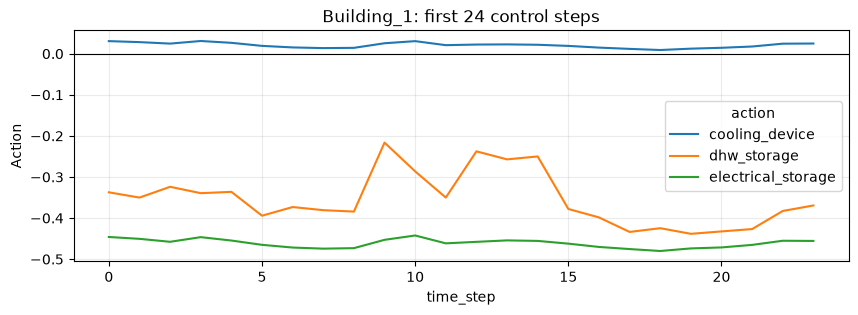

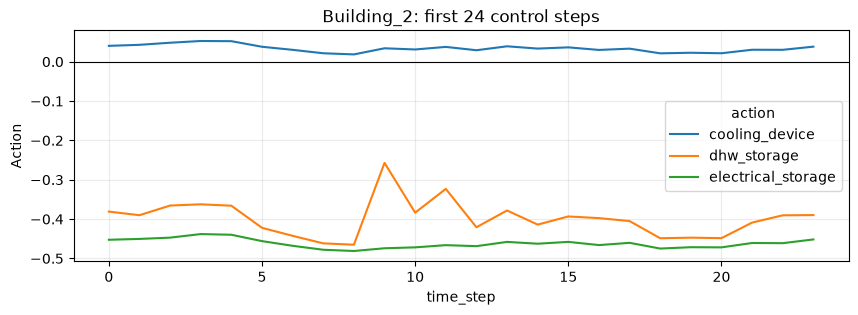

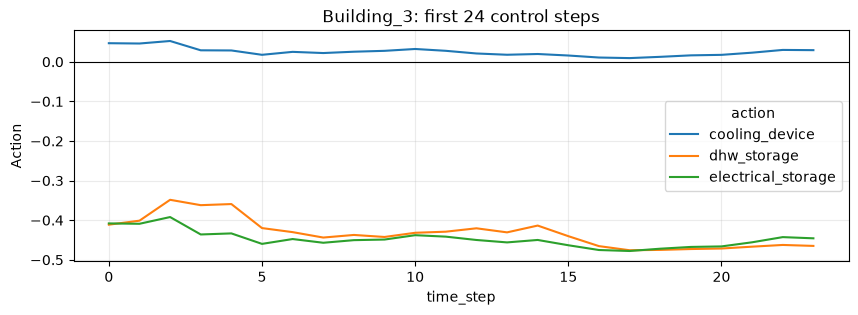

In [7]:
actions = result['actions']
display(actions.head(12))

first_day = actions.query('time_step < 24')
for building_name, building_actions in first_day.groupby('building'):
    action_plot = building_actions.pivot(index='time_step', columns='action', values='value')
    ax = action_plot.plot(figsize=(10, 3), title=f'{building_name}: first 24 control steps')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_ylabel('Action')
    ax.grid(alpha=0.25)
    plt.show()


## How to interpret this baseline

Check these points after a run:

- **Reward curve:** Is the reward improving after exploration? A noisy curve is normal, but a longer experiment should show whether learning stabilizes.
- **Action use:** Are actions varied, or are they stuck near a bound? Persistent saturation may indicate reward, normalization, or exploration problems.
- **Electricity and carbon KPIs:** Lower grid imports can reduce carbon, but the effect depends on when electricity is consumed and the time-varying carbon intensity.
- **Comfort:** The independent reward does not penalize discomfort. Inspect both the district and per-building discomfort results.
- **Fairness:** Compare the worst building's discomfort with the best building and report the gap. This SAC baseline has no fairness term.

The checkpoint and CSV files are written to `outputs/independent_sac/`. That directory is ignored by Git because model files and generated results can be large. Share final compact tables or figures separately when they are needed in the report.


## Recommended next experiment

1. Confirm that the three-episode run completes and inspect its actions and KPIs.
2. Choose a training and held-out evaluation split rather than reusing the same period.
3. Train longer with at least three fixed seeds and summarize mean and variation.
4. Hold the environment and hyperparameters fixed while changing only the reward: independent electricity, carbon-aware, then carbon-aware with a building-level comfort fairness penalty.
5. Compare all learned agents against the same no-control and RBC references.
